# Weather Patterns Across Major Pakistani Cities: ETL and EDA Pipeline

## 1. Introduction

Weather conditions vary across different cities of Pakistan. Some cities are hotter, while others are colder or receive different amounts of rainfall.

This project analyzes daily weather data from six major Pakistani cities:

- Lahore
- Karachi
- Islamabad
- Peshawar
- Quetta
- Multan

The dataset covers the period from 2020 to 2025 and is collected using the Open-Meteo Historical Weather API.

### Project Objectives

- Analyze temperature patterns across six cities.
- Compare average temperatures.
- Explore monthly rainfall patterns.
- Visualize weather data using graphs.
- Identify useful insights from the dataset.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set graph style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Connect to the SQLite database in read-only mode
conn = sqlite3.connect(
    "file:../data/weather.db?mode=ro",
    uri=True
)

# Load weather data into a pandas DataFrame
df = pd.read_sql_query(
    "SELECT * FROM daily_weather",
    conn
)

# Convert date column into datetime format
df['date'] = pd.to_datetime(df['date'])

print("Database connected successfully!")

Database connected successfully!


In [3]:
# Display first 5 rows
display(df.head())

# Display number of rows and columns
print("Dataset Shape:", df.shape)

# Display column names and data types
df.info()

# Display statistical summary
display(df.describe())

,city,date,temp_max,temp_min,precipitation,wind,temp_avg,year,month,season
0,Islamabad,2020-01-01,15.2,3.0,0.0,11.1,9.10,2020,1,Winter
1,Islamabad,2020-01-02,15.0,7.6,0.0,11.6,11.30,2020,1,Winter
2,Islamabad,2020-01-03,14.6,7.0,1.7,10.6,10.80,2020,1,Winter
3,Islamabad,2020-01-04,12.1,5.0,1.0,10.7,8.55,2020,1,Winter
4,Islamabad,2020-01-05,12.9,3.6,0.2,18.3,8.25,2020,1,Winter


Dataset Shape: (13152, 10)
<class 'pandas.DataFrame'>
RangeIndex: 13152 entries, 0 to 13151
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   city           13152 non-null  str           
 1   date           13152 non-null  datetime64[us]
 2   temp_max       13152 non-null  float64       
 3   temp_min       13152 non-null  float64       
 4   precipitation  13152 non-null  float64       
 5   wind           13152 non-null  float64       
 6   temp_avg       13152 non-null  float64       
 7   year           13152 non-null  int64         
 8   month          13152 non-null  int64         
 9   season         13152 non-null  str           
dtypes: datetime64[us](1), float64(5), int64(2), str(2)
memory usage: 1.2 MB


,date,temp_max,temp_min,precipitation,wind,temp_avg,year,month
count,13152,13152.000000,13152.000000,13152.000000,13152.000000,13152.000000,13152.000000,13152.000000
mean,2022-12-31 12:00:00,28.684930,17.709185,1.513960,14.835690,23.197057,2022.499544,6.521898
min,2020-01-01 00:00:00,-1.000000,-9.100000,0.000000,2.000000,-5.050000,2020.000000,1.000000
25%,2021-07-01 18:00:00,22.900000,11.000000,0.000000,10.200000,16.950000,2021.000000,4.000000
50%,2022-12-31 12:00:00,30.200000,18.800000,0.000000,13.400000,24.950000,2022.500000,7.000000
75%,2024-07-01 06:00:00,34.300000,24.800000,0.200000,18.100000,29.350000,2024.000000,10.000000
max,2025-12-31 00:00:00,47.800000,34.800000,162.300000,47.100000,40.700000,2025.000000,12.000000
std,NaN,7.918855,8.105419,5.527951,6.377192,7.819062,1.708246,3.449117


Average Temperature by City:
city
Karachi      26.559329
Multan       25.953786
Lahore       23.994913
Peshawar     22.779699
Islamabad    21.856820
Quetta       18.037797
Name: temp_avg, dtype: float64


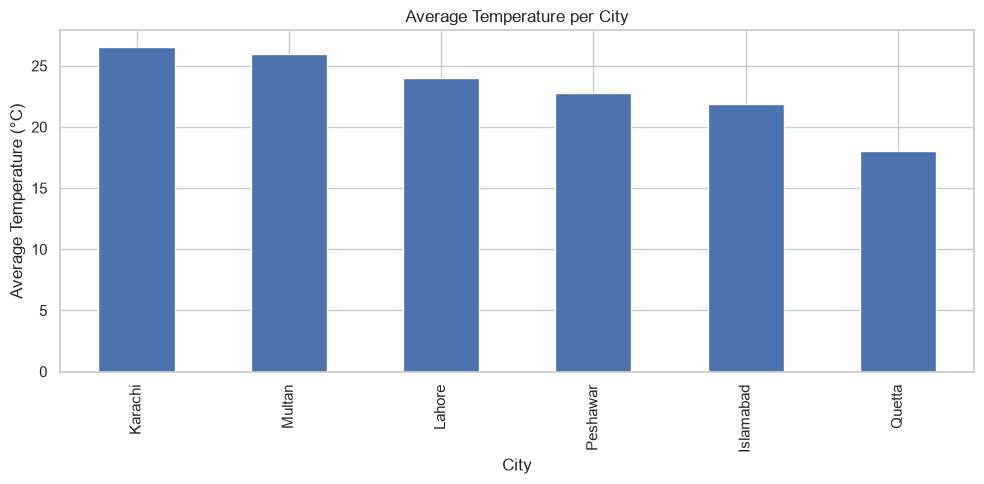

Hottest City: Karachi 26.56 °C
Coldest City: Quetta 18.04 °C


In [4]:

# Calculate average temperature for each city
city_temp = df.groupby('city')['temp_avg'].mean()

# Sort cities from hottest to coldest
city_temp = city_temp.sort_values(ascending=False)

# Display average temperatures
print("Average Temperature by City:")
print(city_temp)

# Create bar chart
plt.figure(figsize=(10, 5))
city_temp.plot(kind='bar')

# Add chart title and axis labels
plt.title('Average Temperature per City')
plt.xlabel('City')
plt.ylabel('Average Temperature (°C)')

# Adjust layout and display chart
plt.tight_layout()
plt.show()

# Find hottest and coldest cities
print("Hottest City:", city_temp.idxmax(), round(city_temp.max(), 2), "°C")
print("Coldest City:", city_temp.idxmin(), round(city_temp.min(), 2), "°C")


### Insight

Karachi has the highest average temperature of 26.56 °C, while Quetta has the lowest average temperature of 18.04 °C. The difference between these cities is 8.52 °C, showing variation in temperature across Pakistani cities.

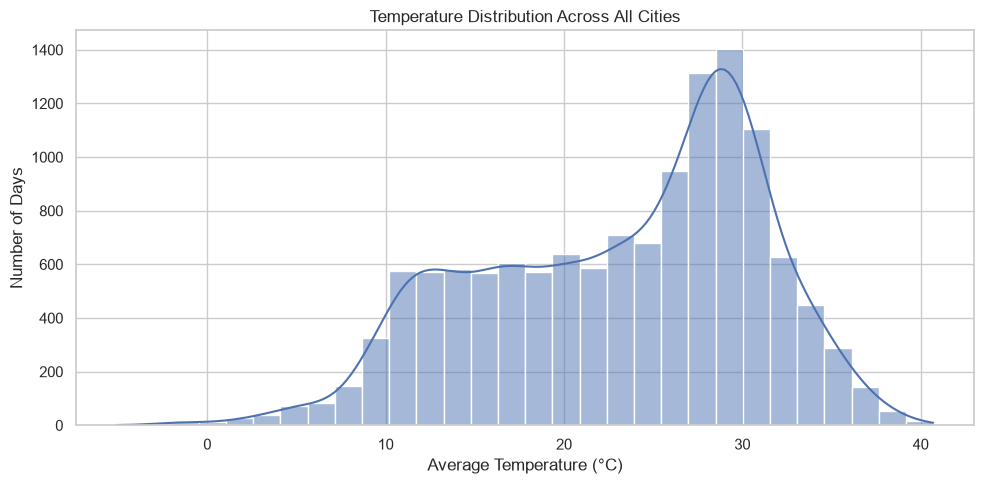

Mean Temperature: 23.2 °C
Minimum Temperature: -5.05 °C
Maximum Temperature: 40.7 °C


In [5]:

# Create temperature distribution histogram
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x='temp_avg', bins=30, kde=True)

plt.title('Temperature Distribution Across All Cities')
plt.xlabel('Average Temperature (°C)')
plt.ylabel('Number of Days')

plt.tight_layout()
plt.show()

# Display temperature statistics
print("Mean Temperature:", round(df['temp_avg'].mean(), 2), "°C")
print("Minimum Temperature:", df['temp_avg'].min(), "°C")
print("Maximum Temperature:", df['temp_avg'].max(), "°C")


### Insight

The histogram shows that most daily average temperatures are concentrated around 28–30 °C. The overall mean temperature is 23.20 °C, while the minimum and maximum temperatures are -5.05 °C and 40.70 °C respectively. This shows considerable temperature variation across the six cities.

Average Monthly Rainfall (mm):
         city  month  precipitation
0   Islamabad      1      83.566667
1   Islamabad      2      54.400000
2   Islamabad      3     123.200000
3   Islamabad      4      68.466667
4   Islamabad      5      36.916667
..        ...    ...            ...
67     Quetta      8      38.650000
68     Quetta      9       0.350000
69     Quetta     10       0.633333
70     Quetta     11       7.666667
71     Quetta     12      12.900000

[72 rows x 3 columns]


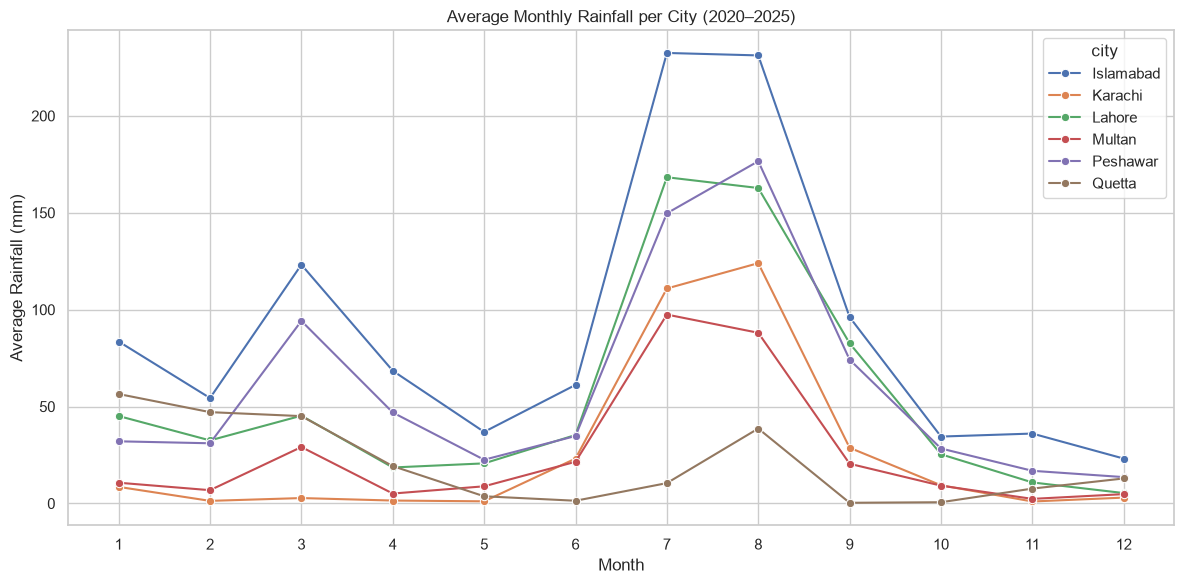

In [6]:

# Calculate total rainfall for each city, year, and month
monthly_rain = df.groupby(
    ['city', 'year', 'month']
)['precipitation'].sum().reset_index()

# Calculate average monthly rainfall across all years
rain_avg = monthly_rain.groupby(
    ['city', 'month']
)['precipitation'].mean().reset_index()

# Display monthly rainfall values
print("Average Monthly Rainfall (mm):")
print(rain_avg)

# Create line chart
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=rain_avg,
    x='month',
    y='precipitation',
    hue='city',
    marker='o'
)

plt.title('Average Monthly Rainfall per City (2020–2025)')
plt.xlabel('Month')
plt.ylabel('Average Rainfall (mm)')
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()


### Insight

The line chart compares the average monthly rainfall of six Pakistani cities from 2020 to 2025. It shows that rainfall patterns vary across cities and months. Some cities receive more rainfall during certain months, while others remain relatively dry.

## Conclusion

- The dataset contains 13,152 daily weather records from six major Pakistani cities covering 2020 to 2025.
- Karachi has the highest average temperature of 26.56 °C, while Quetta has the lowest average temperature of 18.04 °C.
- The temperature distribution shows considerable variation, with an overall mean of 23.20 °C.
- Monthly rainfall patterns differ across cities and months, showing variations in rainfall distribution across Pakistan.

## Viva Questions and Answers

**Q1. What is EDA?**

EDA stands for Exploratory Data Analysis. It is used to understand data through statistics and visualizations.

**Q2. Which libraries are used in this notebook?**

We used Pandas for data handling, SQLite3 for database connection, Matplotlib and Seaborn for data visualization.

**Q3. Why did we use SQLite in read-only mode?**

We used read-only mode to access the database without accidentally modifying or deleting the original data.

**Q4. What does a histogram show?**

A histogram shows the distribution of numerical data. In our project, it shows how average temperatures are distributed across all six cities.

**Q5. Why did we use a line chart for monthly rainfall?**

We used a line chart to compare monthly rainfall patterns across six cities and identify changes over different months.